# Experiment 5 - Data Visualization for AI Models: T5 Translation and BLEU


In [ ]:
!pip -q install transformers sentencepiece sacrebleu torch matplotlib pandas

In [ ]:
import torch, pandas as pd, matplotlib.pyplot as plt
import sacrebleu
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_NAME = "google-t5/t5-small"
device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)
model.eval()
print("Model:", MODEL_NAME, "| device:", device)

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Model: google-t5/t5-small | device: cpu


In [ ]:
english = [
    "Hello, how are you?",
    "I love artificial intelligence.",
    "The weather is very good today.",
    "I am a computer science student.",
    "Cricket is a popular sport.",
    "The coach gives useful advice."
]
reference = [
    "Bonjour, comment allez-vous ?",
    "J'aime l'intelligence artificielle.",
    "Le temps est très beau aujourd'hui.",
    "Je suis étudiant en informatique.",
    "Le cricket est un sport populaire.",
    "L'entraîneur donne des conseils utiles."
]

translations, scores = [], []
for src, ref in zip(english, reference):
    prompt = "translate English to French: " + src
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True).to(device)
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=48, num_beams=4)
    translated = tokenizer.decode(output[0], skip_special_tokens=True)
    bleu = sacrebleu.sentence_bleu(translated, [ref]).score
    translations.append(translated); scores.append(bleu)
    print("English:", src, "\nReference:", ref, "\nGenerated:", translated, "\nSentence BLEU:", round(bleu,2), "\n")

results = pd.DataFrame({"English":english, "Reference French":reference,
                        "Generated French":translations, "Sentence BLEU":scores})
display(results)
print("Mean sentence BLEU:", round(float(results["Sentence BLEU"].mean()),2))

English: Hello, how are you? 
Reference: Bonjour, comment allez-vous ? 
Generated: Bonjour, comment êtes-vous? 
Sentence BLEU: 42.73 

English: I love artificial intelligence. 
Reference: J'aime l'intelligence artificielle. 
Generated: J'aime l'intelligence artificielle. 
Sentence BLEU: 100.0 

English: The weather is very good today. 
Reference: Le temps est très beau aujourd'hui. 
Generated: Les conditions météorologiques sont très bonnes aujourd'hui. 
Sentence BLEU: 12.22 

English: I am a computer science student. 
Reference: Je suis étudiant en informatique. 
Generated: Je suis un étudiant en informatique. 
Sentence BLEU: 48.89 

English: Cricket is a popular sport. 
Reference: Le cricket est un sport populaire. 
Generated: Le cricket est un sport populaire. 
Sentence BLEU: 100.0 

English: The coach gives useful advice. 
Reference: L'entraîneur donne des conseils utiles. 
Generated: L'entraîneur donne des conseils utiles. 
Sentence BLEU: 100.0 



,English,Reference French,Generated French,Sentence BLEU
0,"Hello, how are you?","Bonjour, comment allez-vous ?","Bonjour, comment êtes-vous?",42.728701
1,I love artificial intelligence.,J'aime l'intelligence artificielle.,J'aime l'intelligence artificielle.,100.000000
2,The weather is very good today.,Le temps est très beau aujourd'hui.,Les conditions météorologiques sont très bonne...,12.223076
3,I am a computer science student.,Je suis étudiant en informatique.,Je suis un étudiant en informatique.,48.892302
4,Cricket is a popular sport.,Le cricket est un sport populaire.,Le cricket est un sport populaire.,100.000000
5,The coach gives useful advice.,L'entraîneur donne des conseils utiles.,L'entraîneur donne des conseils utiles.,100.000000


Mean sentence BLEU: 67.31


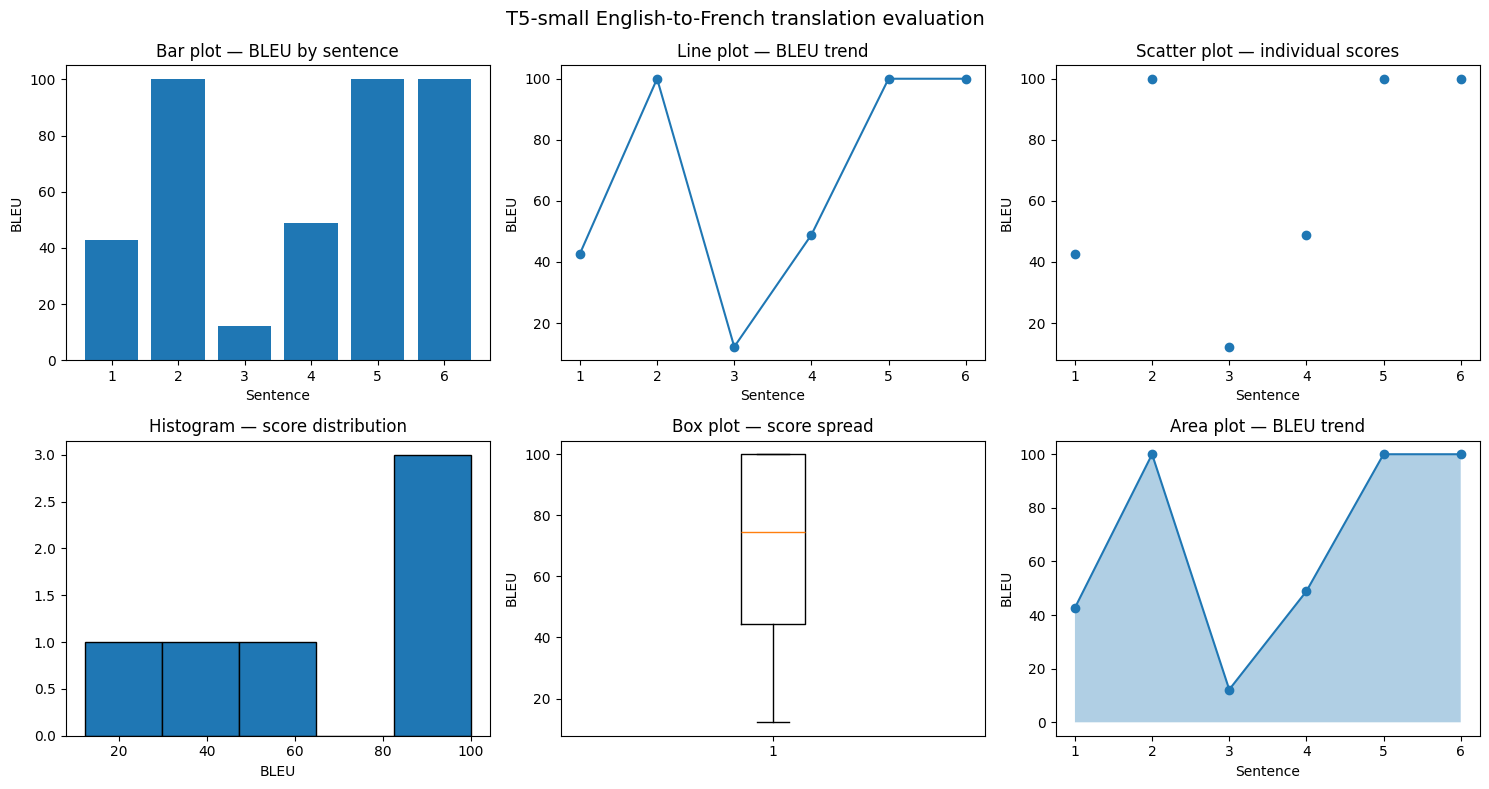

In [ ]:
x = list(range(1, len(scores)+1))
fig, axes = plt.subplots(2,3,figsize=(15,8))
axes[0,0].bar(x,scores); axes[0,0].set_title("Bar plot — BLEU by sentence"); axes[0,0].set_xlabel("Sentence"); axes[0,0].set_ylabel("BLEU")
axes[0,1].plot(x,scores,marker="o"); axes[0,1].set_title("Line plot — BLEU trend"); axes[0,1].set_xlabel("Sentence"); axes[0,1].set_ylabel("BLEU")
axes[0,2].scatter(x,scores); axes[0,2].set_title("Scatter plot — individual scores"); axes[0,2].set_xlabel("Sentence"); axes[0,2].set_ylabel("BLEU")
axes[1,0].hist(scores,bins=5,edgecolor="black"); axes[1,0].set_title("Histogram — score distribution"); axes[1,0].set_xlabel("BLEU")
axes[1,1].boxplot(scores); axes[1,1].set_title("Box plot — score spread"); axes[1,1].set_ylabel("BLEU")
axes[1,2].fill_between(x,scores,alpha=.35); axes[1,2].plot(x,scores,marker="o"); axes[1,2].set_title("Area plot — BLEU trend"); axes[1,2].set_xlabel("Sentence"); axes[1,2].set_ylabel("BLEU")
plt.suptitle("T5-small English-to-French translation evaluation",fontsize=14)
plt.tight_layout(); plt.show()

In [ ]:
results.to_csv("experiment5_translation_bleu_results.csv", index=False)
print("Saved experiment5_translation_bleu_results.csv")

Saved experiment5_translation_bleu_results.csv
